# Applied Statistics Assessment

This notebook investigates the Iris dataset using descriptive statistics, correlation, hypothesis testing, and analysis of variance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df = iris.frame
df.columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species_code"
]

df["species"] = df["species_code"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species_code,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 flowers from three species. This section investigates the distribution of petal length for the complete dataset and for each species.

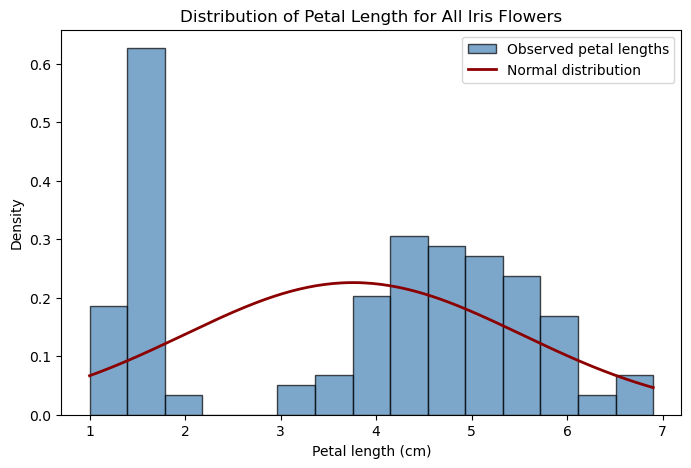

Mean petal length: 3.76 cm
Standard deviation: 1.77 cm


In [2]:
petal_length = df["petal_length"]

mean_petal_length = petal_length.mean()
std_petal_length = petal_length.std()

x = np.linspace(
    petal_length.min(),
    petal_length.max(),
    200
)

plt.figure(figsize=(8, 5))

plt.hist(
    petal_length,
    bins=15,
    density=True,
    alpha=0.7,
    color="steelblue",
    edgecolor="black",
    label="Observed petal lengths"
)

plt.plot(
    x,
    stats.norm.pdf(x, mean_petal_length, std_petal_length),
    color="darkred",
    linewidth=2,
    label="Normal distribution"
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Density")
plt.title("Distribution of Petal Length for All Iris Flowers")
plt.legend()
plt.show()

print(f"Mean petal length: {mean_petal_length:.2f} cm")
print(f"Standard deviation: {std_petal_length:.2f} cm")

Setosa: mean = 1.46 cm, standard deviation = 0.17 cm
Versicolor: mean = 4.26 cm, standard deviation = 0.47 cm
Virginica: mean = 5.55 cm, standard deviation = 0.55 cm


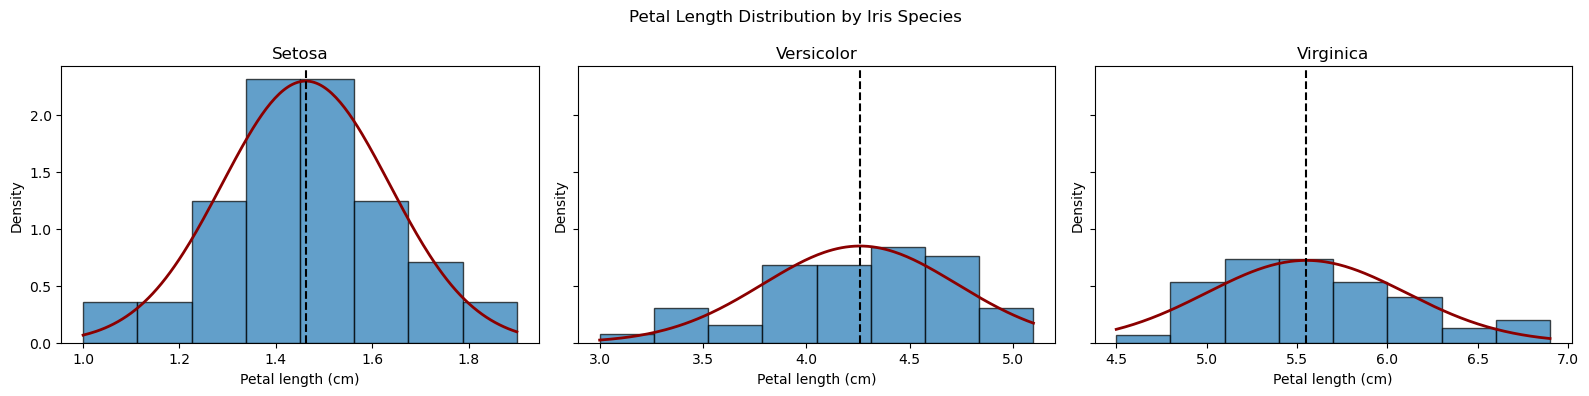

In [3]:
species_order = ["setosa", "versicolor", "virginica"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, species in zip(axes, species_order):
    values = df.loc[df["species"] == species, "petal_length"]
    species_mean = values.mean()
    species_std = values.std()

    x_species = np.linspace(
        values.min(),
        values.max(),
        200
    )

    ax.hist(
        values,
        bins=8,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    ax.plot(
        x_species,
        stats.norm.pdf(x_species, species_mean, species_std),
        color="darkred",
        linewidth=2
    )

    ax.set_title(species.capitalize())
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Density")
    ax.axvline(species_mean, color="black", linestyle="--")

    print(
        f"{species.capitalize()}: "
        f"mean = {species_mean:.2f} cm, "
        f"standard deviation = {species_std:.2f} cm"
    )

plt.suptitle("Petal Length Distribution by Iris Species")
plt.tight_layout()
plt.show()

### Interpretation

Petal length differs clearly between the three Iris species. Setosa has the smallest average petal length and the lowest variability. Versicolor and virginica have larger average petal lengths, with virginica having the largest mean.

The overall distribution is not well represented by a single normal distribution because it is strongly multimodal. This occurs because the three species have distinctly different petal-length distributions. Within each species, however, the distributions appear approximately unimodal and reasonably close to a normal shape.

## Problem 2: Correlation Between Petal Length and Petal Width

This section investigates the relationship between petal length and petal width for the complete Iris dataset and for each species.

Pearson correlation: r = 0.963
p-value: 4.6750e-86


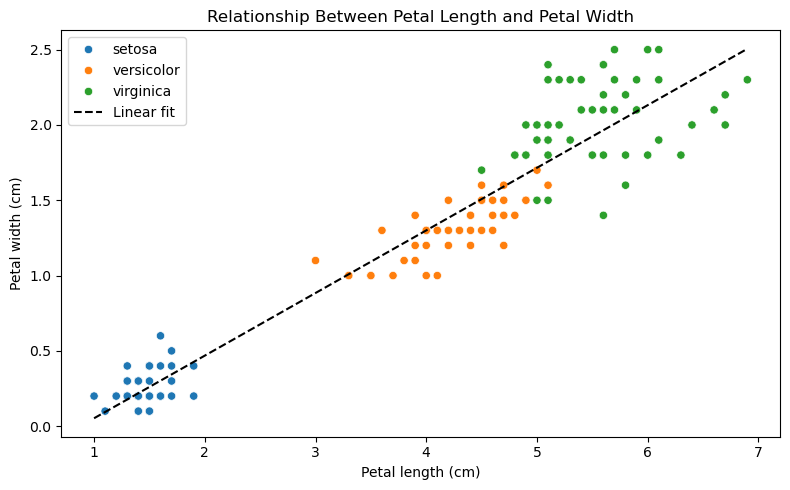

In [4]:
# Pearson correlation for the complete dataset
correlation_all, p_value_all = stats.pearsonr(
    df["petal_length"],
    df["petal_width"]
)

print(f"Pearson correlation: r = {correlation_all:.3f}")
print(f"p-value: {p_value_all:.4e}")

# Scatter plot with a fitted linear regression line
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species"
)

slope, intercept = np.polyfit(
    df["petal_length"],
    df["petal_width"],
    1
)

x_values = np.linspace(
    df["petal_length"].min(),
    df["petal_length"].max(),
    100
)

plt.plot(
    x_values,
    slope * x_values + intercept,
    color="black",
    linestyle="--",
    label="Linear fit"
)

plt.title("Relationship Between Petal Length and Petal Width")
plt.xlabel("Petal length (cm)")
plt.ylabel("Petal width (cm)")
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
# Pearson correlation for each Iris species
species_results = []

for species in iris.target_names:
    species_data = df[df["species"] == species]

    correlation, p_value = stats.pearsonr(
        species_data["petal_length"],
        species_data["petal_width"]
    )

    species_results.append({
        "species": species,
        "correlation_r": correlation,
        "p_value": p_value
    })

correlation_table = pd.DataFrame(species_results)

correlation_table

,species,correlation_r,p_value
0,setosa,0.331630,1.863892e-02
1,versicolor,0.786668,1.271916e-11
2,virginica,0.322108,2.253577e-02


In [6]:
# Pearson correlation for each Iris species
species_results = []

for species in iris.target_names:
    species_data = df[df["species"] == species]

    correlation, p_value = stats.pearsonr(
        species_data["petal_length"],
        species_data["petal_width"]
    )

    species_results.append({
        "species": species,
        "correlation_r": correlation,
        "p_value": p_value
    })

correlation_table = pd.DataFrame(species_results)

correlation_table

,species,correlation_r,p_value
0,setosa,0.331630,1.863892e-02
1,versicolor,0.786668,1.271916e-11
2,virginica,0.322108,2.253577e-02


In [7]:
# Pearson correlation for each Iris species
species_results = []

for species in iris.target_names:
    species_data = df[df["species"] == species]

    correlation, p_value = stats.pearsonr(
        species_data["petal_length"],
        species_data["petal_width"]
    )

    species_results.append({
        "species": species,
        "correlation_r": correlation,
        "p_value": p_value
    })

correlation_table = pd.DataFrame(species_results)

correlation_table

,species,correlation_r,p_value
0,setosa,0.331630,1.863892e-02
1,versicolor,0.786668,1.271916e-11
2,virginica,0.322108,2.253577e-02


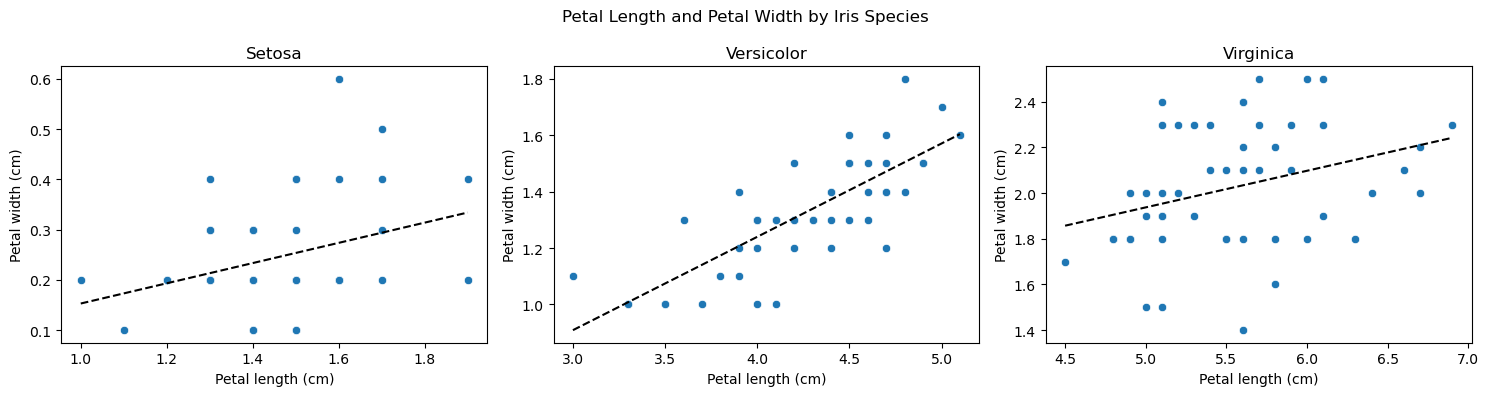

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, species in zip(axes, iris.target_names):
    species_data = df[df["species"] == species]

    sns.scatterplot(
        data=species_data,
        x="petal_length",
        y="petal_width",
        ax=ax
    )

    slope, intercept = np.polyfit(
        species_data["petal_length"],
        species_data["petal_width"],
        1
    )

    x_values = np.linspace(
        species_data["petal_length"].min(),
        species_data["petal_length"].max(),
        100
    )

    ax.plot(
        x_values,
        slope * x_values + intercept,
        color="black",
        linestyle="--"
    )

    ax.set_title(species.capitalize())
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Petal width (cm)")

plt.suptitle("Petal Length and Petal Width by Iris Species")
plt.tight_layout()
plt.show()

### Interpretation

Across all 150 flowers, petal length and petal width show a very strong positive correlation (r = 0.963, p < 0.001). This means that flowers with longer petals generally also tend to have wider petals.

The correlations differ between species. Versicolor shows a strong positive correlation (r = 0.787), while setosa (r = 0.332) and virginica (r = 0.322) show weaker positive correlations. All three p-values are below 0.05, indicating statistically significant relationships within each species.

The stronger overall correlation is partly influenced by the clear differences between the species. Correlation describes association, but it does not establish that increasing petal length causes an increase in petal width.